In [ ]:
import requests
import pandas as pd
import matplotlib.pyplot as plt

url = "https://power.larc.nasa.gov/api/temporal/monthly/point"

parametros = {
    "parameters": "PRECTOTCORR",
    "community": "AG",
    "longitude": 13.49,
    "latitude": -14.92,
    "start": "2015",
    "end": "2025",
    "format": "JSON"
}

resposta = requests.get(url,params=parametros,timeout=60)

print(resposta.status_code)

dados = resposta.json()
print(type(dados))
print(dados.keys())

chuva = dados["properties"]["parameter"]["PRECTOTCORR"]
print(chuva)

df = pd.DataFrame(chuva.items(),columns=["data", "precipitacao"])
print(df.head())
print(df.info())
print(df.tail())

200
<class 'dict'>
dict_keys(['type', 'geometry', 'properties', 'header', 'messages', 'parameters', 'times'])
{'201501': 1.53, '201502': 1.25, '201503': 9.12, '201504': 0.41, '201505': 0.02, '201506': 0.0, '201507': 0.0, '201508': 0.03, '201509': 0.0, '201510': 0.16, '201511': 0.75, '201512': 2.83, '201513': 1.35, '201601': 5.96, '201602': 9.54, '201603': 5.38, '201604': 0.89, '201605': 0.0, '201606': 0.0, '201607': 0.0, '201608': 0.0, '201609': 0.01, '201610': 0.13, '201611': 1.75, '201612': 1.74, '201613': 2.09, '201701': 1.45, '201702': 4.51, '201703': 4.47, '201704': 1.51, '201705': 0.08, '201706': 0.03, '201707': 0.0, '201708': 0.0, '201709': 0.03, '201710': 1.17, '201711': 3.28, '201712': 3.17, '201713': 1.62, '201801': 4.1, '201802': 3.14, '201803': 6.64, '201804': 3.98, '201805': 0.16, '201806': 0.01, '201807': 0.01, '201808': 0.06, '201809': 0.01, '201810': 0.14, '201811': 0.08, '201812': 0.46, '201813': 1.56, '201901': 0.84, '201902': 1.03, '201903': 1.38, '201904': 0.1, '201

In [ ]:
# Criar uma cópia da tabela original
df_limpo = df.copy()

# Transformar a coluna data em texto
df_limpo["data"] = df_limpo["data"].astype(str)

# Manter apenas datas com 6 algarismos
df_limpo = df_limpo[
df_limpo["data"].str.fullmatch(r"\d{6}")].copy()

# Separar o ano e o mês
df_limpo["ano"] = df_limpo["data"].str[:4].astype(int)
df_limpo["mes"] = df_limpo["data"].str[4:6].astype(int)

# Manter apenas os meses válidos de 1 a 12 (removendo o 13 que é a média anual)
df_limpo = df_limpo[
    df_limpo["mes"].between(1, 12)].copy()

# Mostrar os resultados
print(df_limpo.head())
print("Número de registos:", len(df_limpo))

     data  precipitacao   ano  mes
0  201501          1.53  2015    1
1  201502          1.25  2015    2
2  201503          9.12  2015    3
3  201504          0.41  2015    4
4  201505          0.02  2015    5
Número de registos: 132


In [ ]:
print("Total de registos:", len(df_limpo))

print("Anos encontrados:")
print(sorted(df_limpo["ano"].unique()))

print("Meses encontrados:")
print(sorted(df_limpo["mes"].unique()))

Total de registos: 132
Anos encontrados:
[np.int64(2015), np.int64(2016), np.int64(2017), np.int64(2018), np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024), np.int64(2025)]
Meses encontrados:
[np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12)]


In [ ]:
# Dicionário com os nomes dos meses
nomes_meses = {
    1: "Janeiro",
    2: "Fevereiro",
    3: "Março",
    4: "Abril",
    5: "Maio",
    6: "Junho",
    7: "Julho",
    8: "Agosto",
    9: "Setembro",
    10: "Outubro",
    11: "Novembro",
    12: "Dezembro"
}

# Calcular a precipitação média de cada mês
media_mensal = df_limpo.groupby("mes")["precipitacao"].mean()

# Transformar o resultado numa tabela
df_media = media_mensal.reset_index()

# Acrescentar os nomes dos meses
df_media["nome_mes"] = df_media["mes"].map(nomes_meses)

# Mostrar a tabela final
display(df_media)

,mes,precipitacao,nome_mes
0,1,2.960000,Janeiro
1,2,4.449091,Fevereiro
2,3,6.973636,Março
3,4,2.121818,Abril
4,5,0.083636,Maio
5,6,0.004545,Junho
6,7,0.000909,Julho
7,8,0.012727,Agosto
8,9,0.052727,Setembro
9,10,0.351818,Outubro


In [ ]:
# Definir o limiar de precipitação
limiar = 50

# Identificar os meses abaixo do limiar
df_media["risco_potencial"] = df_media["precipitacao"] < limiar

# Mostrar os resultados
print(df_media[["nome_mes", "precipitacao", "risco_potencial"]])

     nome_mes  precipitacao  risco_potencial
0     Janeiro      2.960000             True
1   Fevereiro      4.449091             True
2       Março      6.973636             True
3       Abril      2.121818             True
4        Maio      0.083636             True
5       Junho      0.004545             True
6       Julho      0.000909             True
7      Agosto      0.012727             True
8    Setembro      0.052727             True
9     Outubro      0.351818             True
10   Novembro      1.323636             True
11   Dezembro      1.891818             True


<function matplotlib.pyplot.show(close=None, block=None)>

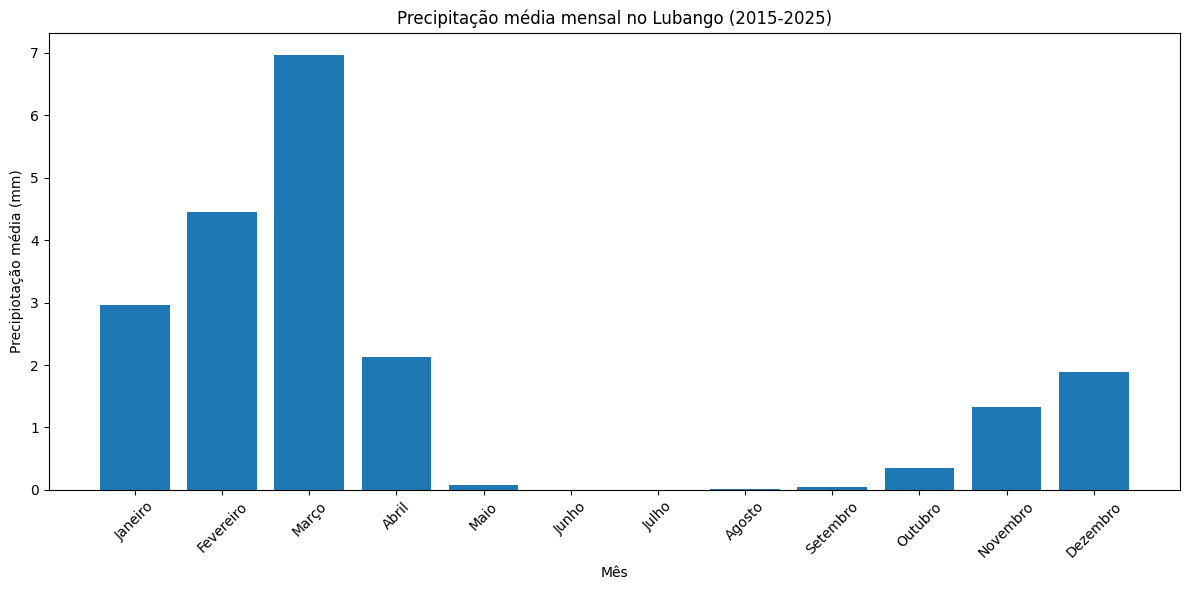

In [ ]:
import matplotlib.pyplot as plt

# Criar a figura
plt.figure(figsize=(12, 6))

# Criar as barras
plt.bar(
    df_media["nome_mes"],
    df_media["precipitacao"]
)

# Adicionar o título e os nomes dos textos
plt.title("Precipitação média mensal no Lubango (2015-2025)")
plt.xlabel("Mês")
plt.ylabel("Precipiotação média (mm)")

# Rodar os nomes dos meses para facilitar a leitura
plt.xticks(rotation=45)

# Ajustar o espaço da figura
plt.tight_layout()

# Mostrar o gráfico
plt.show

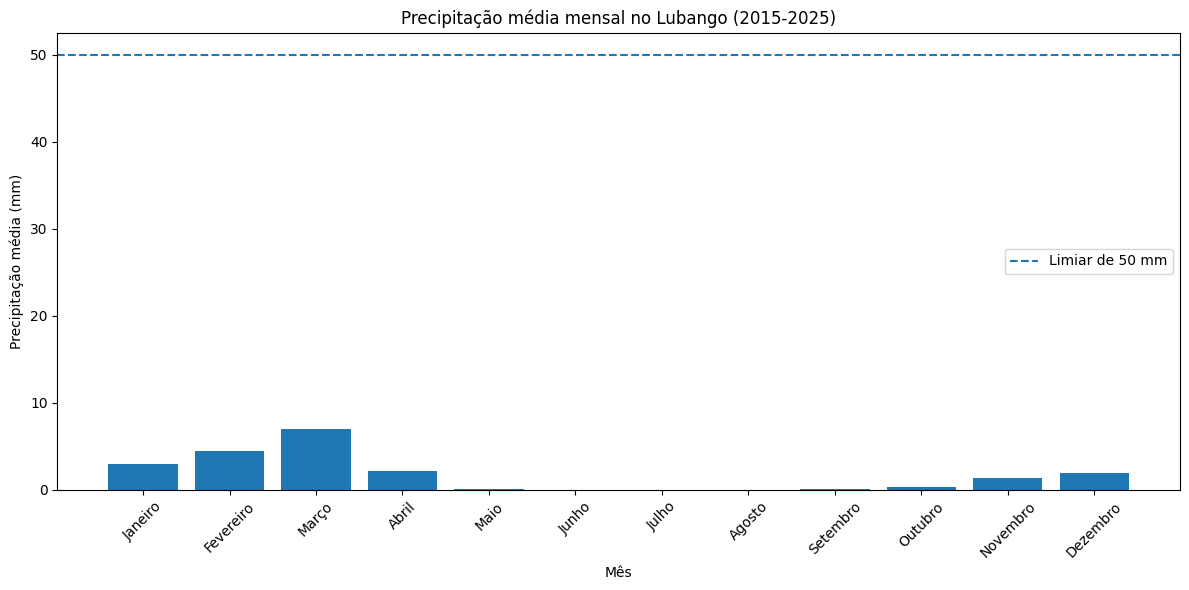

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

# Criar uma barra para cada mês
plt.bar(
    df_media["nome_mes"],
    df_media["precipitacao"]
)

# Desenhar uma linha no nível de 50 mm
plt.axhline(
    y = 50,
    linestyle="--",
    label="Limiar de 50 mm"
)

plt.title("Precipitação média mensal no Lubango (2015-2025)")
plt.xlabel("Mês")
plt.ylabel("Precipitação média (mm)")

plt.xticks(rotation=45)

# Mostrar a legenda
plt.legend()

plt.tight_layout()
plt.show()

In [ ]:
meses_baixa_chuva = df_media[
    df_media["precipitacao"] < 50
]

print("Meses com precipitação média inferior a 50 mm:")

print(
    meses_baixa_chuva[
        ["nome_mes", "precipitacao"]
    ]
)

Meses com precipitação média inferior a 50 mm:
     nome_mes  precipitacao
0     Janeiro      2.960000
1   Fevereiro      4.449091
2       Março      6.973636
3       Abril      2.121818
4        Maio      0.083636
5       Junho      0.004545
6       Julho      0.000909
7      Agosto      0.012727
8    Setembro      0.052727
9     Outubro      0.351818
10   Novembro      1.323636
11   Dezembro      1.891818


In [ ]:
# Endereço da API diária da NASA POWER
url_diaria = "https://power.larc.nasa.gov/api/temporal/daily/point"

# Parâdo pedido
parametros_diarios = {
    "parameters": "PRECTOTCORR",
    "community": "AG",
    "longitude": 13.49,
    "latitude": -14.92,
    "start": "20150101",
    "end": "20251231",
    "format": "JSON"
}

# Fazer o pedido
resposta_diaria = requests.get(
    url_diaria,
    params=parametros_diarios,
    timeout=120
    )
# Verificar se o pedido funcionou
print("Código HTTP:", resposta_diaria.status_code)

# Converter a resposta para um dicionário Python
dados_diarios = resposta_diaria.json()

# Extrair os valores diários de precipitação
chuva_diaria = dados_diarios[
    "properties"
    ]["parameter"]["PRECTOTCORR"]

# Criar uma tabela com os dados diários
df_diario = pd.DataFrame(
    chuva_diaria.items(),
    columns=["data", "precipitacao"]
)

# Converter as datas para o formato de data do pandas
df_diario["data"] = pd.to_datetime(
    df_diario["data"],
    format="%Y%m%d",
    errors="coerce"
)

# Converter precipitação para valores numéricos
df_diario["precipitacao"] = pd.to_numeric(
    df_diario["precipitacao"],
    errors="coerce"
)

# Remover datas ou valores inválidos
df_diario = df_diario.dropna(
    subset=["data", "precipitacao"]
)

# Mostrar as primeiras linhas
print(df_diario.head())

Código HTTP: 200
        data  precipitacao
0 2015-01-01          0.07
1 2015-01-02          0.00
2 2015-01-03          0.01
3 2015-01-04          0.01
4 2015-01-05          0.00


In [ ]:
# Definir data como índice da tabela
df_diario = df_diario.set_index("data")

# Somar precipitação diária de cada mês
chuva_mensal = df_diario["precipitacao"].resample("MS").sum(min_count=1)

# Transformar o resultado numa tabela
df_mensal = chuva_mensal.reset_index()

# Mostrar os primeiros meses
print(df_mensal.head())

# Verificar o número de registos
print("Total de meses:", len(df_mensal))

        data  precipitacao
0 2015-01-01         47.36
1 2015-02-01         35.08
2 2015-03-01        282.87
3 2015-04-01         12.37
4 2015-05-01          0.56
Total de meses: 132


In [ ]:
# Extrair o número do mês
df_mensal["mes"] = df_mensal["data"].dt.month

# Nomes dos meses
nomes_meses = {
    1: "Janeiro",
    2: "Fevereiro",
    3: "Março",
    4: "Abril",
    5: "Maio",
    6: "Junho",
    7: "Julho",
    8: "Agosto",
    9: "Setembro",
    10: "Outubro",
    11: "Novembro",
    12: "Dezembro"
}

# Calcular a média de cada mês do calendário
df_media = df_mensal.groupby("mes")["precipitacao"].mean().reset_index()

# Acrescentar os nomes
df_media["nome_mes"] = df_media["mes"].map(nomes_meses)

# Mostrar os resultados
print(df_media)

    mes  precipitacao   nome_mes
0     1     91.730000    Janeiro
1     2    126.431818  Fevereiro
2     3    216.218182      Março
3     4     63.648182      Abril
4     5      2.627273       Maio
5     6      0.140909      Junho
6     7      0.024545      Julho
7     8      0.357273     Agosto
8     9      1.561818   Setembro
9    10     10.895455    Outubro
10   11     39.687273   Novembro
11   12     58.631818   Dezembro


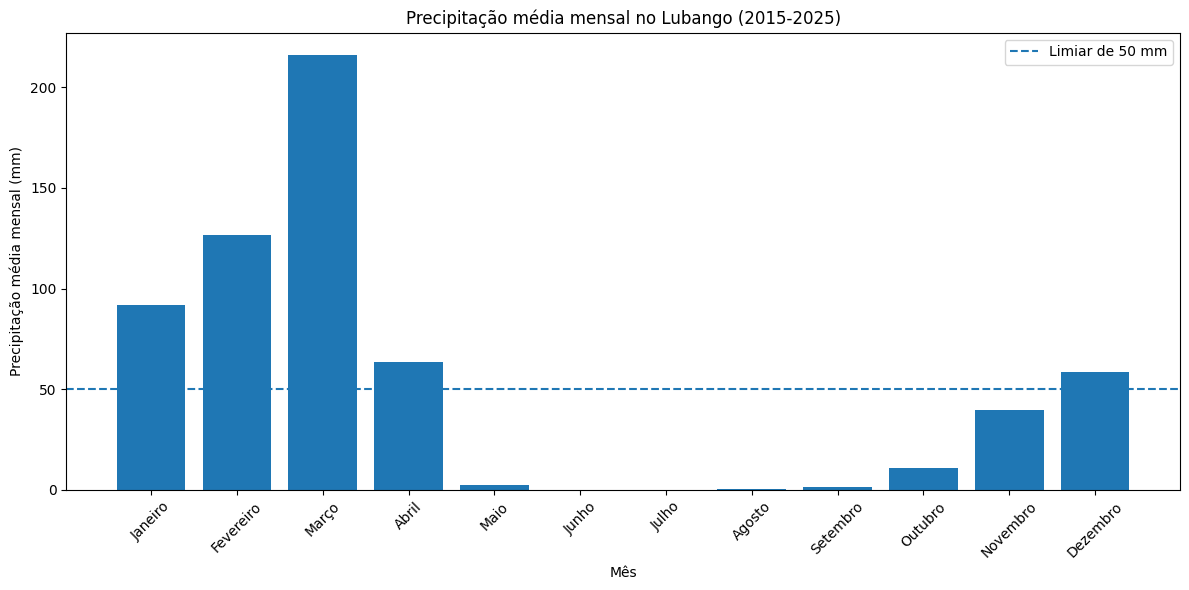

In [ ]:
import matplotlib.pyplot as plt
plt.figure(figsize=(12, 6))

plt.bar(
    df_media["nome_mes"],
    df_media["precipitacao"]
)

plt.axhline(
    y=50,
    linestyle="--",
    label="Limiar de 50 mm"
)

plt.title(
    "Precipitação média mensal no Lubango (2015-2025)"
)

plt.xlabel("Mês")
plt.ylabel("Precipitação média mensal (mm)")

plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
print("Código HTTP:",
resposta_diaria.status_code)

print("Unidade indicada pela NASA:")

print(
    dados_diarios["parameters"]
    ["PRECTOTCORR"]
)

Código HTTP: 200
Unidade indicada pela NASA:
{'units': 'mm/day', 'longname': 'Precipitation Corrected'}


In [ ]:
print(dados_diarios.keys())
print(dados_diarios.get("header", {}))

dict_keys(['type', 'geometry', 'properties', 'header', 'messages', 'parameters', 'times'])
{'title': 'NASA/POWER Source Native Resolution Daily Data', 'api': {'version': 'v2.10.0', 'name': 'POWER Daily API'}, 'sources': ['MERRA2'], 'fill_value': -999.0, 'time_standard': 'LST', 'start': '20150101', 'end': '20251231'}


In [ ]:
print(df_diario.head(10))

print("Data inicial:",
      df_diario.index.min())

print("Data final:",
      df_diario.index.max())

            precipitacao
data                    
2015-01-01          0.07
2015-01-02          0.00
2015-01-03          0.01
2015-01-04          0.01
2015-01-05          0.00
2015-01-06          0.00
2015-01-07          0.00
2015-01-08          0.01
2015-01-09          0.01
2015-01-10          0.01
Data inicial: 2015-01-01 00:00:00
Data final: 2025-12-31 00:00:00


In [ ]:
# Garantir que a coluna 'data' volta a ser uma coluna comum caso seja o índice
if "data" not in df_diario.columns:
    df_diario = df_diario.reset_index()

df_diario = df_diario.sort_values("data")

df_mensal = (df_diario.set_index("data")["precipitacao"].resample("MS").sum(min_count=1).reset_index())

df_mensal.columns = ["data", "precipitacao_mensal"]

print(df_mensal.head(12))

         data  precipitacao_mensal
0  2015-01-01                47.36
1  2015-02-01                35.08
2  2015-03-01               282.87
3  2015-04-01                12.37
4  2015-05-01                 0.56
5  2015-06-01                 0.00
6  2015-07-01                 0.00
7  2015-08-01                 0.81
8  2015-09-01                 0.06
9  2015-10-01                 4.88
10 2015-11-01                22.46
11 2015-12-01                87.74


In [ ]:
df_mensal["mes"] = df_mensal["data"].dt.month
df_media = (df_mensal.groupby("mes")["precipitacao_mensal"].mean().reset_index())

nomes_meses = {
    1: "Janeiro",
    2: "Fevereiro",
    3: "Março",
    4: "Abril",
    5: "Maio",
    6: "Junho",
    7: "Julho",
    8: "Agosto",
    9: "Setembro",
    10: "Outubro",
    11: "Novembro",
    12: "Dezembro"
}

df_media["nome_mes"] = df_media["mes"].map(nomes_meses)

print(df_media[["nome_mes", "precipitacao_mensal"]].round(2))

     nome_mes  precipitacao_mensal
0     Janeiro                91.73
1   Fevereiro               126.43
2       Março               216.22
3       Abril                63.65
4        Maio                 2.63
5       Junho                 0.14
6       Julho                 0.02
7      Agosto                 0.36
8    Setembro                 1.56
9     Outubro                10.90
10   Novembro                39.69
11   Dezembro                58.63


In [ ]:
limiar = 50

# Correção: Alterado "precipitacao" para "precipitacao_mensal"
meses_baixa_chuva = df_media[df_media["precipitacao_mensal"] < limiar]

print("Meses com média inferior a 50 mm:")

print(meses_baixa_chuva[["nome_mes", "precipitacao_mensal"]].round(2))

Meses com média inferior a 50 mm:
    nome_mes  precipitacao_mensal
4       Maio                 2.63
5      Junho                 0.14
6      Julho                 0.02
7     Agosto                 0.36
8   Setembro                 1.56
9    Outubro                10.90
10  Novembro                39.69


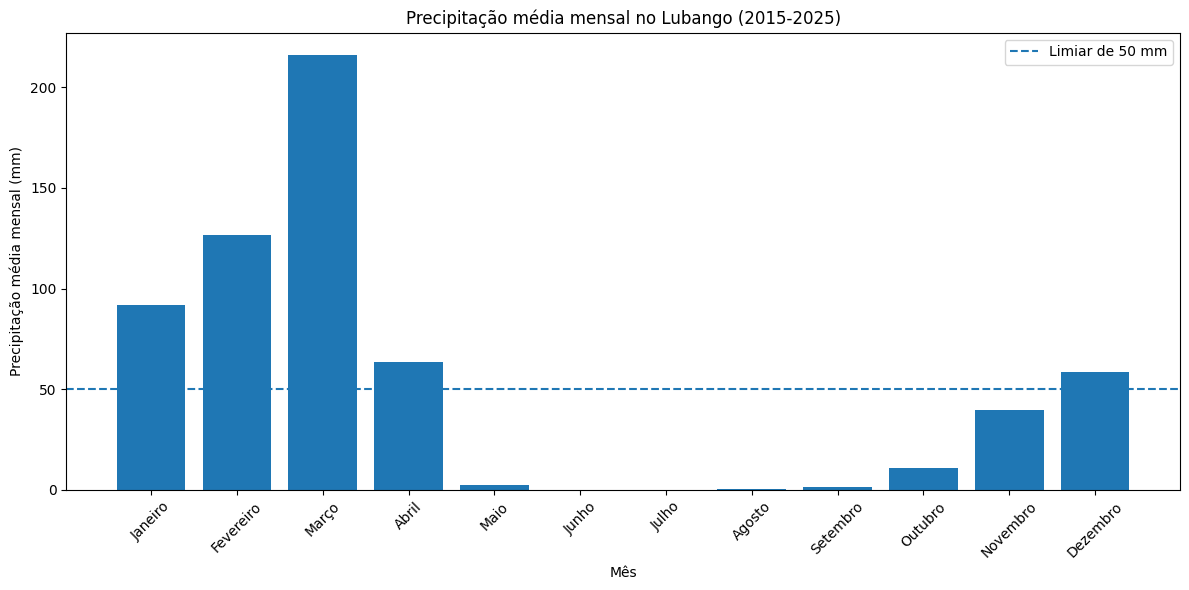

In [ ]:
import matplotlib.pyplot as plt
plt.figure(figsize=(12, 6))

plt.bar(
    df_media["nome_mes"],
    df_media["precipitacao_mensal"]
)

plt.axhline(
    y=50,
    linestyle="--",
    label="Limiar de 50 mm"
)

plt.title(
    "Precipitação média mensal no Lubango (2015-2025)"
)

plt.xlabel("Mês")
plt.ylabel("Precipitação média mensal (mm)")

plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
print(df_media[["nome_mes","precipitacao_mensal"]].round(2))

     nome_mes  precipitacao_mensal
0     Janeiro                91.73
1   Fevereiro               126.43
2       Março               216.22
3       Abril                63.65
4        Maio                 2.63
5       Junho                 0.14
6       Julho                 0.02
7      Agosto                 0.36
8    Setembro                 1.56
9     Outubro                10.90
10   Novembro                39.69
11   Dezembro                58.63


In [ ]:
limiar = 50

meses_secos = df_media[df_media["precipitacao_mensal"] < limiar]

print("Meses com precipitação média inferior a 50 mm:")
print(meses_secos[["nome_mes","precipitacao_mensal"]].round(2))

Meses com precipitação média inferior a 50 mm:
    nome_mes  precipitacao_mensal
4       Maio                 2.63
5      Junho                 0.14
6      Julho                 0.02
7     Agosto                 0.36
8   Setembro                 1.56
9    Outubro                10.90
10  Novembro                39.69
